# Phase 5: Model training and making the submission
In this notebook i compare some simple models and then make the final submission file.

Files needed in the same folder: `features.npz` (phase 4), `splits.npz` (phase 3), `clean_data_v2.npz` (phase 2b, only for the test ids).

Steps
1. load the features and the folds
2. try a few simple models using the folds from phase 3
3. pick the best one and look at where it makes mistakes
4. train it on all the training data and predict the test set
5. save `submission.csv`


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 1. Load the data
`F_train` is the feature table of train windows and `F_test` is for the test windows. `folds` tells which validation fold each train window belongs to (made in phase 3).

In [ ]:
f = np.load("features.npz", allow_pickle=True)
F_train, F_test, y_train = f["F_train"], f["F_test"], f["y_train"]
folds = np.load("splits.npz", allow_pickle=True)["folds"]
test_ids = np.load("clean_data_v2.npz", allow_pickle=True)["test_ids"]

print("train features:", F_train.shape)
print("test features :", F_test.shape)
print("windows in each fold:", np.bincount(folds))

assert len(F_train) == len(y_train) == len(folds)
assert len(F_test) == len(test_ids)
assert np.isfinite(F_train).all() and np.isfinite(F_test).all()

train features: (635, 573)
test features : (403, 573)
windows in each fold: [180 146 125 102  82]


## 2. Models to compare
Only simple models. Some of them need scaled features (knn, logistic regression, svm) because they use distances, so i put a StandardScaler inside a pipeline. This way the scaler is fitted only on the training part of each fold and the validation part is never used for fitting (the project pdf says this).

Trees and random forest dont need scaling.

In [11]:
models = {
    "decision_tree": DecisionTreeClassifier(random_state=0),
    "knn": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "logistic_regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000)),
    "svm": make_pipeline(StandardScaler(), SVC(C=10)),
    "random_forest": RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
   
}

## 3. Validation with the phase 3 folds
For each fold i train on the other 4 folds and test on fold i. I keep the predictions too so i can make a confusion matrix later.

Note: the folds are only pseudo subjects (we dont have real subject ids), so this score is an estimate. It can still be a bit higher than the kaggle score.

In [ ]:
results = {}     
oof_pred = {}     

for name, model in models.items():
    preds = np.empty(len(y_train), dtype=object)
    accs = []
    for k in np.unique(folds):
        tr = folds != k
        va = folds == k
        model.fit(F_train[tr], y_train[tr])
        preds[va] = model.predict(F_train[va])
        accs.append(accuracy_score(y_train[va], preds[va]))
    results[name] = accs
    oof_pred[name] = preds
    print(f"{name:20s} mean = {np.mean(accs):.3f}   folds = {np.round(accs, 3)}")

decision_tree        mean = 0.849   folds = [0.817 0.884 0.768 0.873 0.902]
knn                  mean = 0.929   folds = [0.967 0.945 0.776 0.98  0.976]
logistic_regression  mean = 0.940   folds = [0.961 0.966 0.8   1.    0.976]
svm                  mean = 0.947   folds = [0.967 0.993 0.8   1.    0.976]
random_forest        mean = 0.998   folds = [0.989 1.    1.    1.    1.   ]


In [ ]:

table = pd.DataFrame({
    "mean_acc": {n: np.mean(a) for n, a in results.items()},
    "worst_fold": {n: np.min(a) for n, a in results.items()},
}).sort_values("mean_acc", ascending=False)
print(table.round(3))

best_name = table.index[0]
print("\nbest model:", best_name)

                     mean_acc  worst_fold
random_forest           0.998       0.989
svm                     0.947       0.800
logistic_regression     0.940       0.800
knn                     0.929       0.776
decision_tree           0.849       0.768

best model: random_forest


## 4. Where does the best model make mistakes?
Confusion matrix of the validation predictions. Rows are the true activity, columns are what the model said.

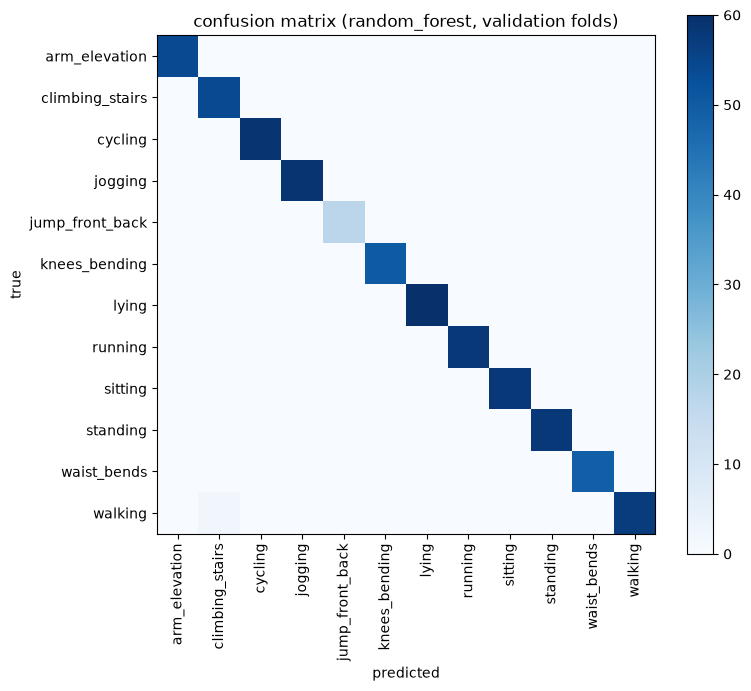

                 precision    recall  f1-score   support

  arm_elevation      1.000     1.000     1.000        54
climbing_stairs      0.964     1.000     0.982        54
        cycling      1.000     1.000     1.000        59
        jogging      1.000     1.000     1.000        59
jump_front_back      1.000     1.000     1.000        17
  knees_bending      1.000     1.000     1.000        50
          lying      1.000     1.000     1.000        60
        running      1.000     1.000     1.000        58
        sitting      1.000     1.000     1.000        58
       standing      1.000     1.000     1.000        58
    waist_bends      1.000     1.000     1.000        49
        walking      1.000     0.966     0.983        59

       accuracy                          0.997       635
      macro avg      0.997     0.997     0.997       635
   weighted avg      0.997     0.997     0.997       635



In [14]:
labels = sorted(np.unique(y_train))
cm = confusion_matrix(y_train, oof_pred[best_name], labels=labels)

plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title(f"confusion matrix ({best_name}, validation folds)")
plt.colorbar()
plt.tight_layout()
plt.show()

print(classification_report(y_train, oof_pred[best_name], digits=3))

## 5. Final model and testing on the test set
Now i train the best model on **all** the training windows (every fold together) and predict the test set. The test labels are hidden so there is no accuracy here, kaggle will tell us the score.

I also look at the predicted class counts. The test set should have a mix of all activities, so if the model says one class for almost everything something is wrong.

In [15]:
final_model = models[best_name]
final_model.fit(F_train, y_train)

test_pred = final_model.predict(F_test)

print("predicted test windows:", len(test_pred))
print(pd.Series(test_pred).value_counts())

predicted test windows: 403
jogging            48
standing           47
knees_bending      39
arm_elevation      37
lying              35
walking            35
cycling            35
waist_bends        35
climbing_stairs    35
sitting            24
running            22
jump_front_back    11
Name: count, dtype: int64


## 6. Make submission.csv
The format is two columns `id` and `target`, one row for every test id, no index column and nothing else.

In [ ]:
submission = pd.DataFrame({"id": test_ids, "target": test_pred})
submission.to_csv("submission.csv", index=False)


check = pd.read_csv("submission.csv")
print(check.shape)
print(list(check.columns))
print(check.head())
assert list(check.columns) == ["id", "target"]
assert len(check) == 403
assert check["id"].is_unique
assert check["target"].isin(labels).all()
print("submission looks fine")

(403, 2)
['id', 'target']
         id           target
0  TE000001    knees_bending
1  TE000002    knees_bending
2  TE000003          jogging
3  TE000004         standing
4  TE000005  jump_front_back
submission looks fine


## Notes for the report
- Compared 6 simple models on the phase 3 folds, best one was picked from the table above.
- Scaling is inside the pipeline so it is fitted only on training folds.
- The folds are pseudo subjects so the validation score is just an estimate of how it does on new people.
- Final model is trained on all train windows and used on the test set.